In [1]:
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.spatial import procrustes
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
print(sys.version)
print(os.getcwd())

3.14.0 (v3.14.0:ebf955df7a8, Oct  7 2025, 08:20:14) [Clang 16.0.0 (clang-1600.0.26.6)]
/Users/kailashnah/Documents/Personal/Study Material/Assignments/Unsupervised Machine Learning/final/osmi-clustering/notebooks


## 1. Loading and exploring the dataset

In [2]:
df = pd.read_csv("../data/mental-health-in-tech-2016_20161114.csv")

In [3]:
# shape of the dataset
df.shape

(1433, 63)

In [4]:
# number of self-employed people
df["Are you self-employed?"].value_counts()

Are you self-employed?
0    1146
1     287
Name: count, dtype: int64

In [5]:
employees = df[df["Are you self-employed?"] == 0].copy()
employees["Are you self-employed?"].value_counts()

Are you self-employed?
0    1146
Name: count, dtype: int64

In [6]:
employees.shape

(1146, 63)

## 2. Filtering the dataset
We are filtering the dataset to only include employees since HR of a company is only interested in the mental health of their employees. This means that we will drop columns that don't have answers at all and also the column that states if they're employed or not

In [7]:
employees_clean = employees.dropna(axis=1, how="all")
employees_clean.shape

(1146, 55)

In [8]:
employees.columns.difference(employees_clean.columns)

Index(['Do you believe your productivity is ever affected by a mental health issue?',
       'Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?',
       'Do you know local or online resources to seek help for a mental health disorder?',
       'If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?',
       'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?',
       'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?',
       'If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?',
       'If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?'],
      dtype='str')

In [9]:
employees_clean = employees_clean.drop(columns=["Are you self-employed?"])

In [10]:
employees_clean.shape

(1146, 54)

## 3. Exploratory Data Analysis

#### Getting an overview of all 54 columns

In [11]:
for index, col in enumerate(employees_clean):
    print(f"{index + 1}. {employees_clean[col].value_counts(dropna=False)}")
    print("\n----------------------------------------\n")

1. How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

----------------------------------------

2. Is your employer primarily a tech company/organization?
1.0    883
0.0    263
Name: count, dtype: int64

----------------------------------------

3. Is your primary role within your company related to tech/IT?
NaN    883
1.0    248
0.0     15
Name: count, dtype: int64

----------------------------------------

4. Does your employer provide mental health benefits as part of healthcare coverage?
Yes                                531
I don't know                       319
No                                 213
Not eligible for coverage / N/A     83
Name: count, dtype: int64

----------------------------------------

5. Do you know the options for mental health care available under your employer-provided coverage?
No          

In [12]:
employees_clean["What is your age?"].describe()

count    1146.000000
mean       33.655323
std        11.703277
min         3.000000
25%        28.000000
50%        32.000000
75%        38.000000
max       323.000000
Name: What is your age?, dtype: float64

#### Visualizing the age distribution of employees

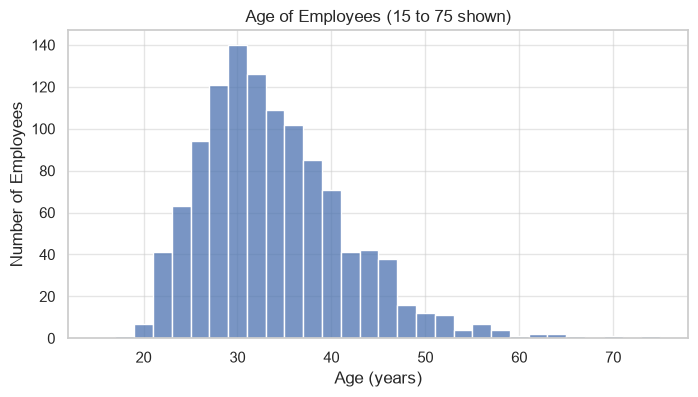

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(data=employees_clean, bins=30, binrange=(15, 75), x="What is your age?")
plt.title("Age of Employees (15 to 75 shown)")
plt.xlabel("Age (years)")
plt.ylabel("Number of Employees")
plt.savefig("../figures/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
employees_clean["How many employees does your company or organization have?"].value_counts()

How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

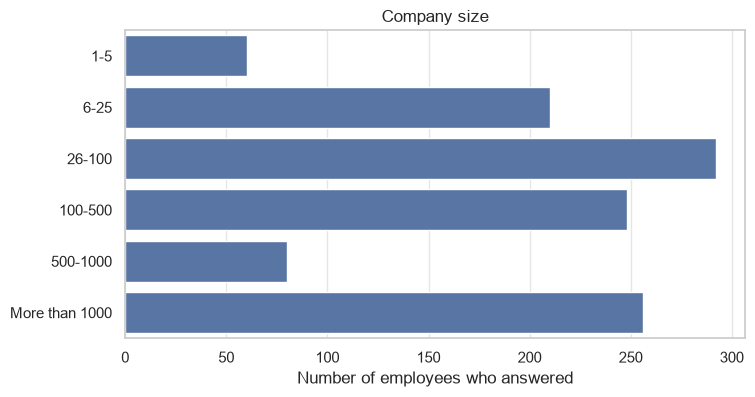

In [15]:
size_order = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="How many employees does your company or organization have?",
    order=size_order,
)
plt.title("Company size")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/company_size.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
remote_work=employees_clean["Do you work remotely?"].value_counts()
remote_work

Do you work remotely?
Sometimes    611
Never        318
Always       217
Name: count, dtype: int64

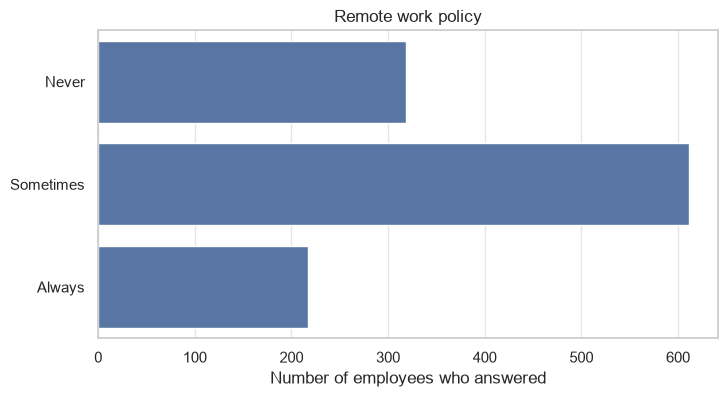

In [17]:
remote_work_order = ["Never", "Sometimes", "Always"]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="Do you work remotely?",
    order=remote_work_order,
)
plt.title("Remote work policy")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/remote_work_policy.png", dpi=150, bbox_inches="tight")
plt.show()

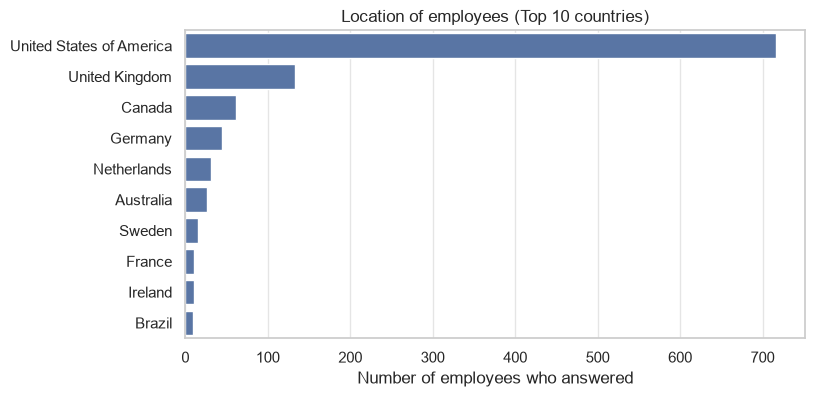

In [18]:
country_order = employees_clean["What country do you work in?"].value_counts().index[:10]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="What country do you work in?",
    order=country_order,
)
plt.title("Location of employees (Top 10 countries)")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/location_employees.png", dpi=150, bbox_inches="tight")
plt.show()

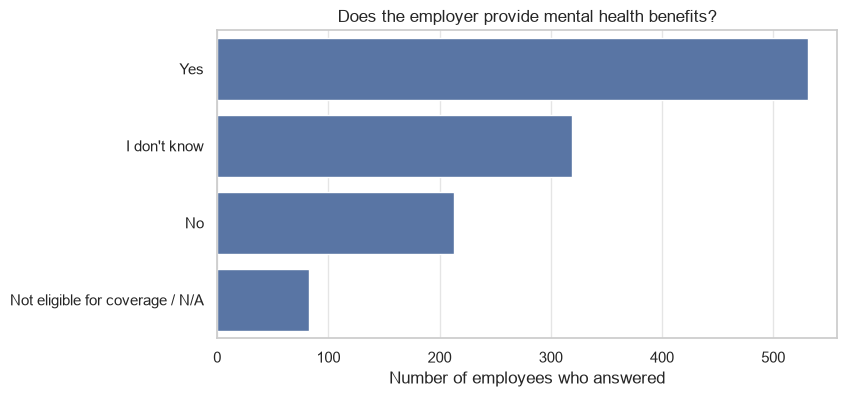

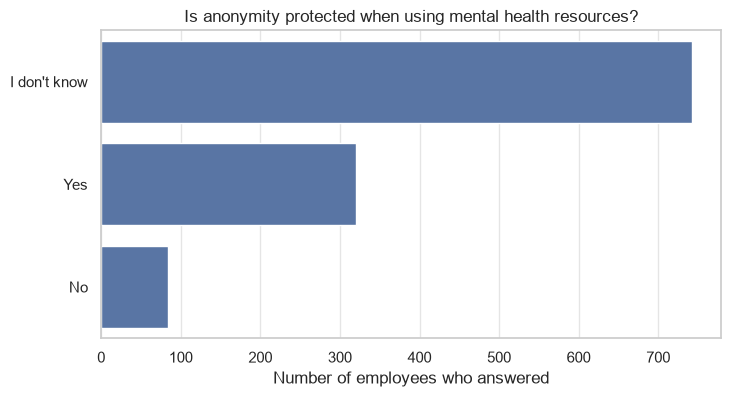

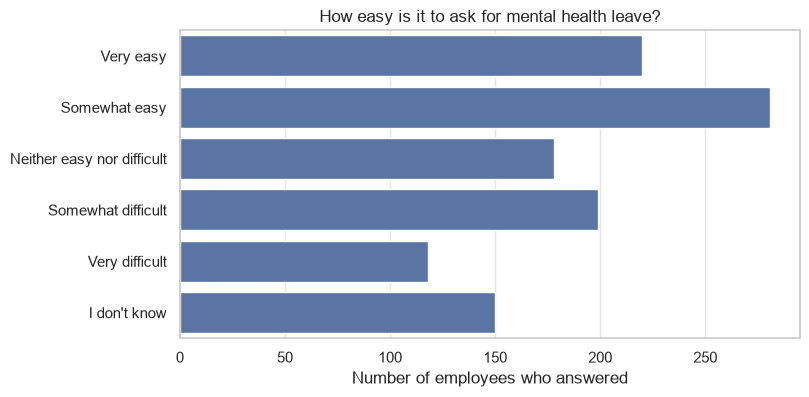

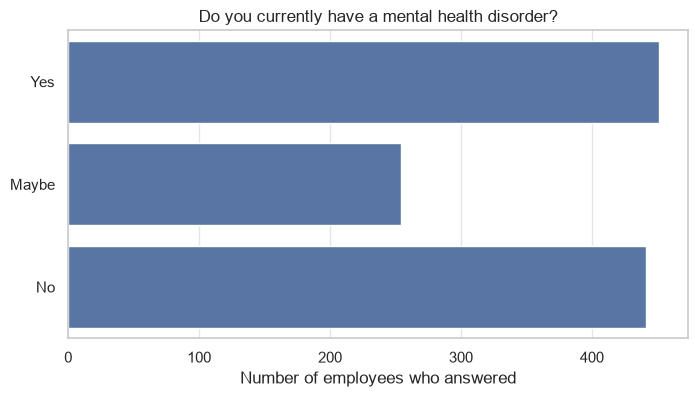

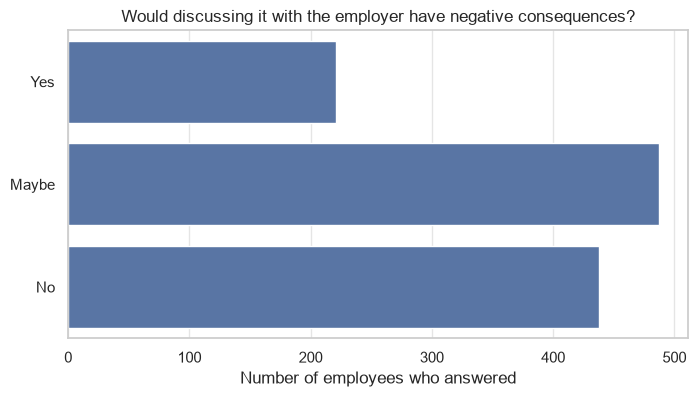

In [19]:
hr_plots = {
    "mh_benefits": {
        "column": "Does your employer provide mental health benefits as part of healthcare coverage?",
        "title": "Does the employer provide mental health benefits?",
        "order": employees_clean["Does your employer provide mental health benefits as part of healthcare coverage?"].value_counts().index,
    },
    "anonymity": {
        "column": "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?",
        "title": "Is anonymity protected when using mental health resources?",
        "order": employees_clean["Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?"].value_counts().index,
    },
    "medical_leave": {
        "column": "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
        "title": "How easy is it to ask for mental health leave?",
        "order": ["Very easy", "Somewhat easy", "Neither easy nor difficult",
          "Somewhat difficult", "Very difficult", "I don't know"],
    },
    "current_disorder": {
        "column": "Do you currently have a mental health disorder?",
        "title": "Do you currently have a mental health disorder?",
        "order": ["Yes", "Maybe", "No"],
    },
    "negative_consequences": {
        "column": "Do you think that discussing a mental health disorder with your employer would have negative consequences?",
        "title": "Would discussing it with the employer have negative consequences?",
        "order": ["Yes", "Maybe", "No"],
    },
}

for name, plot in hr_plots.items():
    column = plot["column"]

    # safety check: any answer in the data that's missing from my order list?
    forgotten = set(employees_clean[column].dropna().unique()) - set(plot["order"])
    assert not forgotten, f"{name}: these answers are missing from the order list: {forgotten}"

    plt.figure(figsize=(8, 4))
    sns.countplot(data=employees_clean, y=column, order=plot["order"])
    plt.title(plot["title"])
    plt.xlabel("Number of employees who answered")
    plt.ylabel("")
    plt.savefig(f"../figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

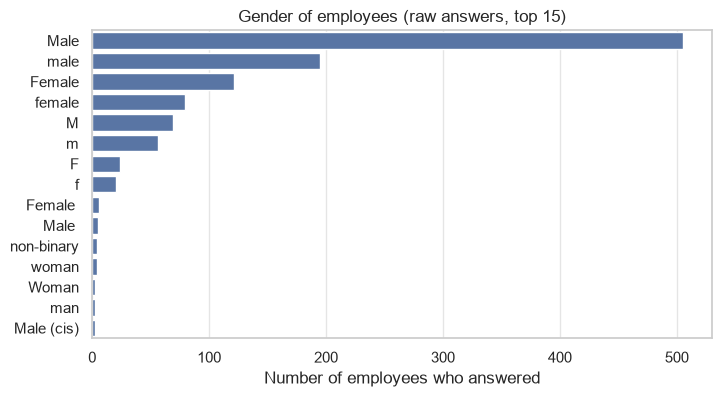

In [20]:
genders = employees_clean["What is your gender?"].value_counts().index[:15]

plt.figure(figsize=(8, 4))
sns.countplot(data=employees_clean, y="What is your gender?", order=genders)
plt.title("Gender of employees (raw answers, top 15)")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/gender_employees.png", dpi=150, bbox_inches="tight")
plt.show()

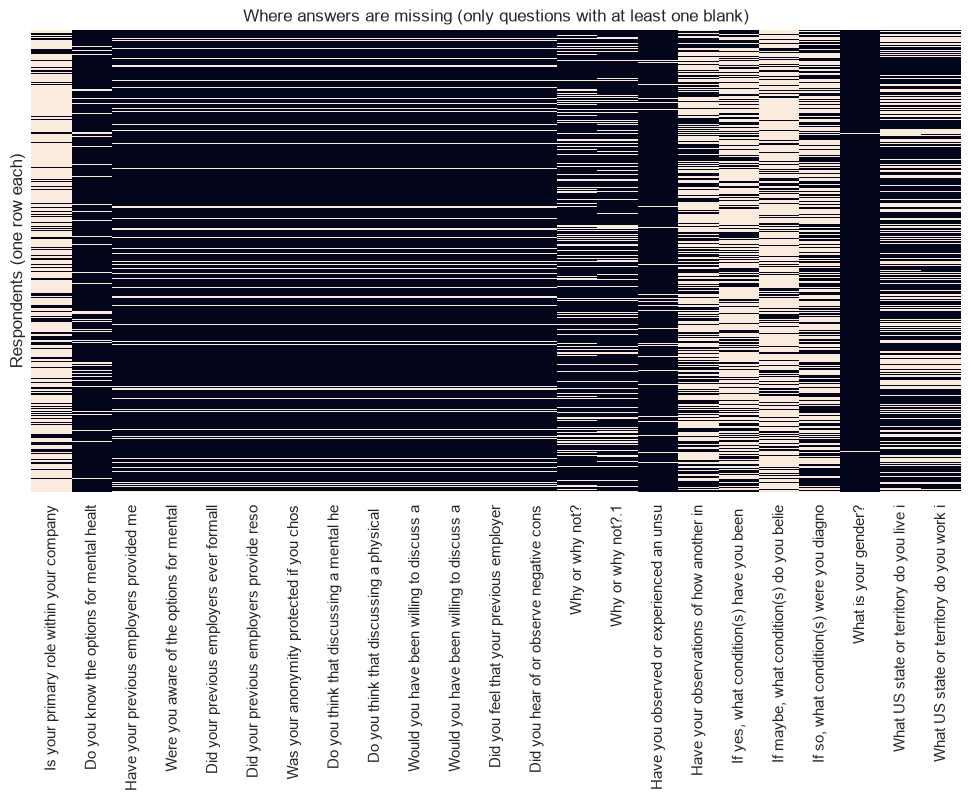

In [21]:
has_missing = employees_clean.columns[employees_clean.isna().any()]

plt.figure(figsize=(12, 6))
sns.heatmap(
    employees_clean[has_missing].isna(),
    cbar=False,
    xticklabels=[c[:40] for c in has_missing],
    yticklabels=False,
)
plt.title("Where answers are missing (only questions with at least one blank)")
plt.ylabel("Respondents (one row each)")
plt.savefig("../figures/missingness_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## EDA notes

### 1. Who answered (sample description)
- 1146 employees after filtering. 62.5% work in the USA and 11.6% in the UK,
  so results lean heavily towards US workplaces. Keep this in mind when
  transferring findings to our company (limitation for the report).
- Age: 32 (median)
- Company size: 26-100 (25.5%), More than 1000 (22.3%)
- Remote work: Sometimes 53.3%, Never 27.7%, Always 18.9%

### 2. Data quality problems (fix in step 4)
- Age contains impossible values: 3, 17, 99 and 323. Only 4 rows, but they
  stretch the histogram badly. Needs a rule in step 4 (e.g. outside 18 to 75 -> missing).
- Gender: 61 different spellings, 21 with a trailing space, 3 blank
- Work position: 180 different combinations (several roles ticked, separated by `|`)

### 3. Missing values (from the heatmap)
- "Is your primary role related to tech/IT?" is 77% blank because it was only
  asked when the employer is NOT a tech company. Structural, not random:
  do not fill with a median. Probably drop in step 5.
- Previous-employer block: 11.4% (People with no previous employer)
- Condition free-text columns: 51% to 78% (Only asked after “Yes” or “Maybe”)
- US state columns: about 38% (Only asked of people in the USA)
- Observations of how another individual...” had around 55.4% missing values since they were only asked if they had observed something.

### 4. Findings relevant to HR
- 64.7% of employees answered "I don't know" when asked whether their anonymity
  is protected when using mental health resources. Only 27.9% said yes.
  This is a communication gap HR could fix cheaply.
- Benefits: 27.8% didn't know if they had mental health benefits
- Career fears: 46.1% (only 12.7% say no) thought it would have or already has hurt their career
- Employer takes mental health seriously: 43.0% don't know if their employer takes mental health as seriously as physical health.

### 5. Decisions for later steps
- Strip spaces from gender before cleaning (step 4).
- A rule needs to be added for impossible ages.
- The free-text columns must be dropped.
- The columns with skip-logic blanks must not be filled with a median.

## 4. Cleaning

In [22]:
gender_raw = employees_clean["What is your gender?"].str.strip().str.lower()

# Checked in this order; the first rule that matches decides the group
gender_rules = [
    ("Unknown", r"^(human|none of your business|fm)$"),
    ("Other", r"\b(trans\w*|ftm|m2f|non-binary|nonbinary|nb|enby|genderqueer|genderfluid|genderflux"
              r"|agender|bigender|androgynous|queer|other|multi-gender|assigned at birth|bodied)\b"
              r"|\bmale\b.*\bfemale\b"),
    ("Female", r"\b(female|f|woman|fem)\b"),
    ("Male", r"\b(male|m|man|dude|cisdude|mail)\b"),
]

remaining = sorted(gender_raw.dropna().unique())
gender_map = {}
for group, pattern in gender_rules:
    matched = [answer for answer in remaining if re.search(pattern, answer)]
    for answer in matched:
        gender_map[answer] = group
    remaining = [answer for answer in remaining if answer not in matched]

print("Not matched by any rule:", remaining)

employees_clean["gender_clean"] = gender_raw.map(gender_map)
employees_clean.loc[gender_raw.isna(), "gender_clean"] = "Unknown"
assert employees_clean["gender_clean"].notna().all(), "Some answers got no group"

employees_clean["gender_clean"].value_counts()

Not matched by any rule: []


gender_clean
Male       846
Female     266
Other       28
Unknown      6
Name: count, dtype: int64

In [23]:
gender_audit = pd.crosstab(gender_raw.fillna("(blank)"), employees_clean["gender_clean"])
gender_audit[(gender_audit["Other"] > 0) | (gender_audit["Unknown"] > 0)]

gender_clean,Female,Male,Other,Unknown
What is your gender?,,,,
(blank),0,0,0,3
agender,0,0,2,0
androgynous,0,0,1,0
bigender,0,0,1,0
enby,0,0,1,0
female assigned at birth,0,0,1,0
female or multi-gender femme,0,0,1,0
female-bodied; no feelings about gender,0,0,1,0
fm,0,0,0,1


In [24]:
age = employees_clean["What is your age?"]
impossible_age = (age < 18) | (age > 75)
print("Impossible ages:", impossible_age.sum(), sorted(age[impossible_age]))

employees_clean["age_clean"] = age.mask(impossible_age)
age_median = employees_clean["age_clean"].median()
employees_clean["age_clean"] = employees_clean["age_clean"].fillna(age_median)

print("Median used:", age_median)
employees_clean["age_clean"].describe()

Impossible ages: 4 [3, 17, 99, 323]
Median used: 32.0


count    1146.000000
mean       33.381326
std         7.680541
min        19.000000
25%        28.000000
50%        32.000000
75%        38.000000
max        74.000000
Name: age_clean, dtype: float64

### Cleaning notes

#### Gender
- Problem: 61 spellings (mostly case and trailing-space differences, e.g. “Male” vs “male”), 3 blanks, free-text answers that are not clearly male or female (e.g. “non-binary”, “transgender”, “human”) and other answers that tell us nothing about gender (e.g. “none of your business”).
- What I did:
  - Stripped spaces and lowercased the answers.
  - Created a list of rules to match answers to one of four groups.
  - Applied the rules in order, so the first rule that matches decides the group.
- Why not substring matching / keeping raw top 4:
  - Substring matching would have been too broad and could misclassify answers. For instance, “male” is a substring of “female”, so substring matching would have misclassified many answers.
  - Raw top 4 are Male, male, Female, female, which would have left many answers unclassified.
- Result: Male: 846, Female: 266, Other: 28, Unknown: 6
- Limitation: The number of answers in the Other group is small, so we cannot classify this group properly nor analyze it in detail.

#### Age
- Problem: Cleaning the age column and dealing with impossible values (3, 17, 99, 323) that stretch the histogram badly.
- What I did:
  - Identified and masked the impossible values.
  - Filled the missing values with the median age.
- Why not deleting rows / clipping:
  - Those 4 people’s other ~50 answers are valid, and keeping them keeps n = 1146, consistent with the EDA.
  - Clipping would distort the distribution of ages. 323 and 99 would become 75, which is a huge jump and would misrepresent the data, 3 would become 18, which is also a huge jump and would misrepresent the data. And finally 17 would become 18, which is a small jump but still misrepresents the data.
- Result: 4 rows changed, median 32.0, range 19 to 74
- Limitation: While the four people get an assumed age of 32 (which has a negligible effect), the 18 year cutoff might wrongly exclude a real 17 year old apprentice.

#### What I deliberately did NOT do
- Did not fill skip-logic blanks with a median.
  - What skip logic is: the survey form changed depending on earlier answers, so some
    questions were never shown to some people. A blank there means "not asked", not
    "forgot to answer". Example: people with no previous employer never saw the
    previous-employer questions.
  - Families affected (23 of 54 columns have blanks):
    - Previous employer (11 questions, 11.4% each): only asked if they had a previous employer.
    - "Is your primary role related to tech/IT?" (77.1%): only asked if the employer is not a tech company.
    - Condition free text (3 columns, 51% to 78%): only asked after answering Yes or Maybe.
    - "Why or why not?" (2 columns, 22% to 24%): optional explanation boxes.
    - US state, live in / work in (about 38%): only asked of people in the USA.
    - "Observations of how another individual..." (55.4%): only asked if they had observed something.
    - Two smaller ones (4.5% and 11.6%) are probably also skip logic; checked in step 5.
  - Evidence: all 11 previous-employer questions are missing for exactly 11.4% of people.
    Random forgetting would never give the same number 11 times.
  - Why a median would be wrong: it would invent an answer to a question the person never
    saw, e.g. give someone with no previous employer an opinion about that employer. In
    clustering, these fake "average" answers would pull unrelated people together.
  - What instead: decided per family in step 5, either drop the column or keep
    "not asked" as its own value.
- "I don't know" is not treated as missing. It is a real answer and is handled in step 6 (encoding).

## 5. Feature Selection

In [25]:
text_cols = employees_clean.select_dtypes(exclude="number")
print(text_cols.nunique().sort_values(ascending=False).head(12))

Why or why not?                                                                              863
Why or why not?.1                                                                            860
Which of the following best describes your work position?                                    180
If yes, what condition(s) have you been diagnosed with?                                      101
If so, what condition(s) were you diagnosed with?                                             90
If maybe, what condition(s) do you believe you have?                                          77
What is your gender?                                                                          61
What US state or territory do you work in?                                                    48
What US state or territory do you live in?                                                    47
What country do you work in?                                                                  44
What country do you live in?  

In [26]:
free_text_cols = [
    "Why or why not?",
    "Why or why not?.1",
    "If yes, what condition(s) have you been diagnosed with?",
    "If maybe, what condition(s) do you believe you have?",
    "If so, what condition(s) were you diagnosed with?",
]
features = employees_clean.drop(columns=free_text_cols)
print(employees_clean.shape, "->", features.shape)

(1146, 56) -> (1146, 51)


In [27]:
raw_cols = ["What is your gender?", "What is your age?"]
profile_cols = ["gender_clean", "age_clean"]

features = features.drop(columns=raw_cols + profile_cols)
print(features.shape)

(1146, 47)


In [28]:
features = features.drop(columns=["Is your primary role within your company related to tech/IT?"])
print(features.shape)

(1146, 46)


In [29]:
no_prev = features["Do you have previous employers?"] == 0
prev_cols = features.columns[
    features[no_prev].isna().all() & features[~no_prev].notna().all()
]
assert len(prev_cols) == 11, prev_cols

features[prev_cols] = features[prev_cols].fillna("No previous employer")
print("Blanks left:", features[prev_cols].isna().sum().sum())
features[prev_cols[0]].value_counts()

Blanks left: 0


Have your previous employers provided mental health benefits?
Some did                326
No, none did            280
I don't know            258
Yes, they all did       151
No previous employer    131
Name: count, dtype: int64

In [30]:
parent_col = ("Have you observed or experienced an unsupportive or badly handled response "
              "to a mental health issue in your current or previous workplace?")
obs_col = ("Have your observations of how another individual who discussed a mental health "
           "disorder made you less likely to reveal a mental health issue yourself in your "
           "current workplace?")

obs_table = pd.crosstab(
    features[parent_col].fillna("(blank)"),
    features[obs_col].fillna("(blank)"),
)
obs_table.index.name = "Unsupportive response seen? (parent)"
obs_table.columns.name = "Made you less likely to reveal? (follow-up)"
obs_table

Made you less likely to reveal? (follow-up),(blank),Maybe,No,Yes
Unsupportive response seen? (parent),,,,
(blank),52,0,0,0
Maybe/Not sure,58,63,118,39
No,491,0,0,0
"Yes, I experienced",22,24,36,50
"Yes, I observed",12,45,44,92


#### Observations question: evidence
- What the table shows: the follow-up was only shown to people who did not answer "No" to the parent question.
- The 635 blanks have three causes:
  - 491: answered "No" to the parent, so never shown the question (zero answers in that row)
  - 52: left the parent blank, so the follow-up never appeared
  - 92 (58 + 22 + 12): were shown it but did not answer
- Decision: dropped the column. Its missing values mix three causes (skip logic n = 491, upstream skip n = 52, item non-response n = 92), so no single fill value is valid, and guessing the answers of the 92 would be an assumption.
- What we keep: the parent question, which records whether someone saw or experienced a badly handled response. It is answered by 95% of employees (52 blanks).
- Limitation: we lose the only direct measure of whether seeing a bad response made people less likely to speak up themselves (181 of the 511 who answered said Yes). The parent tells us what people saw, not how it affected them, so this "silencing" effect can only be discussed qualitatively in the report.

In [31]:
features = features.drop(columns=[obs_col])
print(features.shape)

(1146, 45)


In [32]:
features[parent_col] = features[parent_col].fillna("No answer")
features[parent_col].value_counts()

Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
No                    491
Maybe/Not sure        278
Yes, I observed       193
Yes, I experienced    132
No answer              52
Name: count, dtype: int64

#### Unsupportive response question: 52 blanks
52 blanks (4.5%), no skip logic found; these people answered all later questions, so kept and marked ‘No answer’ rather than guessed or dropped.

In [33]:
options_col = "Do you know the options for mental health care available under your employer-provided coverage?"
features[options_col] = features[options_col].fillna("No answer")
features[options_col].value_counts()

Do you know the options for mental health care available under your employer-provided coverage?
No               354
I am not sure    352
Yes              307
No answer        133
Name: count, dtype: int64

#### Coverage options question: 133 blanks
- 133 blanks (11.6%). Nobody with MH benefits left it blank; 127 of the 133 have no or no eligible coverage, so the question mostly did not apply to them.
- Kept the column and marked blanks "No answer". Filling with "No" would mix real "don't know the options" answers with people who never said that.
- Note for step 6: "No" and "Not eligible" in the benefits question are close in meaning; decide whether to merge them.

In [34]:
work_country = features["What country do you work in?"]
features["country_group"] = work_country.where(
    work_country.isin(["United States of America", "United Kingdom"]), "Other"
)

features = features.drop(columns=[
    "What country do you live in?",
    "What country do you work in?",
    "What US state or territory do you live in?",
    "What US state or territory do you work in?",
])
print(features.shape)
features["country_group"].value_counts()

(1146, 42)


country_group
United States of America    716
Other                       297
United Kingdom              133
Name: count, dtype: int64

In [35]:
position_col = "Which of the following best describes your work position?"
position = features[position_col]

dev_roles = ["Back-end Developer", "Front-end Developer", "DevOps/SysAdmin"]
lead_roles = ["Supervisor/Team Lead", "Executive Leadership"]

features["is_developer"] = position.str.contains("|".join(dev_roles)).astype(int)
features["is_leadership"] = position.str.contains("|".join(lead_roles)).astype(int)

features = features.drop(columns=[position_col])
print(features.shape)
pd.crosstab(features["is_developer"], features["is_leadership"])

(1146, 43)


is_leadership,0,1
is_developer,,
0,203,113
1,678,152


In [36]:
rename_map = {
    # Current employer
    "How many employees does your company or organization have?": "company_size",
    "Is your employer primarily a tech company/organization?": "tech_company",
    "Does your employer provide mental health benefits as part of healthcare coverage?": "mh_benefits",
    "Do you know the options for mental health care available under your employer-provided coverage?": "knows_mh_options",
    "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?": "employer_discussed_mh",
    "Does your employer offer resources to learn more about mental health concerns and options for seeking help?": "employer_mh_resources",
    "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?": "anonymity_protected",
    "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:": "medical_leave_ease",
    "Do you think that discussing a mental health disorder with your employer would have negative consequences?": "mh_discussion_neg",
    "Do you think that discussing a physical health issue with your employer would have negative consequences?": "ph_discussion_neg",
    "Would you feel comfortable discussing a mental health disorder with your coworkers?": "comfortable_coworkers",
    "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?": "comfortable_supervisor",
    "Do you feel that your employer takes mental health as seriously as physical health?": "employer_mh_serious",
    "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?": "observed_neg_consequences",
    # Previous employers
    "Do you have previous employers?": "has_prev_employer",
    "Have your previous employers provided mental health benefits?": "prev_mh_benefits",
    "Were you aware of the options for mental health care provided by your previous employers?": "prev_knew_mh_options",
    "Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?": "prev_discussed_mh",
    "Did your previous employers provide resources to learn more about mental health issues and how to seek help?": "prev_mh_resources",
    "Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?": "prev_anonymity_protected",
    "Do you think that discussing a mental health disorder with previous employers would have negative consequences?": "prev_mh_discussion_neg",
    "Do you think that discussing a physical health issue with previous employers would have negative consequences?": "prev_ph_discussion_neg",
    "Would you have been willing to discuss a mental health issue with your previous co-workers?": "prev_willing_coworkers",
    "Would you have been willing to discuss a mental health issue with your direct supervisor(s)?": "prev_willing_supervisor",
    "Did you feel that your previous employers took mental health as seriously as physical health?": "prev_mh_serious",
    "Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?": "prev_observed_neg_consequences",
    # Openness and stigma
    "Would you be willing to bring up a physical health issue with a potential employer in an interview?": "interview_physical",
    "Would you bring up a mental health issue with a potential employer in an interview?": "interview_mental",
    "Do you feel that being identified as a person with a mental health issue would hurt your career?": "career_hurt",
    "Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?": "coworkers_view_negatively",
    "How willing would you be to share with friends and family that you have a mental illness?": "share_friends_family",
    "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?": "unsupportive_response",
    # Personal history
    "Do you have a family history of mental illness?": "family_history",
    "Have you had a mental health disorder in the past?": "past_disorder",
    "Do you currently have a mental health disorder?": "current_disorder",
    "Have you been diagnosed with a mental health condition by a medical professional?": "diagnosed",
    "Have you ever sought treatment for a mental health issue from a mental health professional?": "sought_treatment",
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?": "interferes_treated",
    "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?": "interferes_untreated",
    # Work setup
    "Do you work remotely?": "remote_work",
}
assert len(rename_map) == 40, len(rename_map)

features = features.rename(columns=rename_map, errors="raise")
print(features.shape)
print("Long names left:", [c for c in features.columns if len(c) > 30])
print(list(features.columns))

(1146, 43)
Long names left: []
['company_size', 'tech_company', 'mh_benefits', 'knows_mh_options', 'employer_discussed_mh', 'employer_mh_resources', 'anonymity_protected', 'medical_leave_ease', 'mh_discussion_neg', 'ph_discussion_neg', 'comfortable_coworkers', 'comfortable_supervisor', 'employer_mh_serious', 'observed_neg_consequences', 'has_prev_employer', 'prev_mh_benefits', 'prev_knew_mh_options', 'prev_discussed_mh', 'prev_mh_resources', 'prev_anonymity_protected', 'prev_mh_discussion_neg', 'prev_ph_discussion_neg', 'prev_willing_coworkers', 'prev_willing_supervisor', 'prev_mh_serious', 'prev_observed_neg_consequences', 'interview_physical', 'interview_mental', 'career_hurt', 'coworkers_view_negatively', 'share_friends_family', 'unsupportive_response', 'family_history', 'past_disorder', 'current_disorder', 'diagnosed', 'sought_treatment', 'interferes_treated', 'interferes_untreated', 'remote_work', 'country_group', 'is_developer', 'is_leadership']


In [37]:
assert features.isna().sum().sum() == 0, features.isna().sum()[lambda s: s > 0]
assert features.shape == (1146, 43), features.shape
print("Step 5 done:", features.shape, "and no missing values")

Step 5 done: (1146, 43) and no missing values


## Step 5 summary: feature selection

This step decides which survey answers go into the clustering and how their missing values are handled. Most blanks in this survey come from skip logic (questions shown only after certain earlier answers), so each family of columns was checked against the question that controls it before deciding. Columns were dropped when they could not be used fairly (free text, questions skipped by most people, near-duplicates), and blanks were filled only with labels that state a fact ("No previous employer", "No answer"), never with a guessed answer. Demographics (gender, age) are kept out so the clusters form on attitudes and experiences, which HR can act on.

| Column(s) | Action | Reason |
|---|---|---|
| 2 × "Why or why not?", 3 × condition free text | Dropped | Free text: 860+ unique answers in the "why" columns; one-hot would create hundreds of near-empty columns. NLP is out of scope |
| Raw gender, raw age | Dropped | Replaced by gender_clean and age_clean (step 4) |
| gender_clean, age_clean | Kept out of features | Demographics describe clusters (step 10), they don't build them; otherwise clusters may split by gender instead of answers |
| Tech/IT role | Dropped | Skip logic: blank for exactly the 883 tech-company respondents; filling would invent answers and leave 98.7% one value |
| 11 previous-employer questions | Blanks → "No previous employer" | Blank for exactly the 131 people with no previous employer; true fact, not a guess. Collapse into composite scores in step 7 so it is not counted 11 times |
| Observations follow-up | Dropped | Blanks mix three causes (491 never shown, 52 parent blank, 92 skipped); no single fill value is valid |
| Unsupportive response (parent) | Blanks → "No answer" | 52 item non-responses, no skip logic; those people answered all later questions |
| Coverage options | Blanks → "No answer" | 133 blanks, almost all without coverage; "No" would mix with real unawareness |
| Country live in / work in | → country_group (USA 716, UK 133, Other 297) | Agree for 99.1%; work country is what HR and employment law follow |
| US state live in / work in | Dropped | 38% blank (US only), spread over ~48 states |
| Work position | → is_developer (830), is_leadership (265) | 180 multi-select combinations; flags keep overlapping roles similar |
| 40 remaining questions | Renamed | Short names grouped by family (rename_map = appendix table) |

**Result:** 1146 employees × 43 features, no missing values.

## 6. Encoding

In [38]:
encoded = features.copy()

unknown_answers = {
    "I don't know": "dont_know",
    "No answer": "no_answer",
    "Not applicable to me": "na",
    "Not applicable to me (I do not have a mental illness)": "na",
}


def encode_with_flag(df, col, scale):
    found = [answer for answer in unknown_answers if (df[col] == answer).any()]
    assert len(found) == 1, f"{col}: expected one unknown-type answer, found {found}"
    unknown = found[0]

    midpoint = (min(scale.values()) + max(scale.values())) / 2
    df[f"{col}_{unknown_answers[unknown]}"] = (df[col] == unknown).astype(int)
    df[col] = df[col].map(scale | {unknown: midpoint})
    assert df[col].notna().all(), f"{col}: an answer is missing from the scale"


yes_no = {"No": 0, "Yes": 1}
often_scale = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3}

scales = {
    "medical_leave_ease": {"Very difficult": 0, "Somewhat difficult": 1, "Neither easy nor difficult": 2,
                           "Somewhat easy": 3, "Very easy": 4},
    "mh_benefits": {"No": 0, "Not eligible for coverage / N/A": 0, "Yes": 1},
    "knows_mh_options": {"No": 0, "I am not sure": 1, "Yes": 2},
    "employer_discussed_mh": yes_no,
    "employer_mh_resources": yes_no,
    "anonymity_protected": yes_no,
    "employer_mh_serious": yes_no,
    "family_history": yes_no,
    "share_friends_family": {"Not open at all": 0, "Somewhat not open": 1, "Neutral": 2,
                             "Somewhat open": 3, "Very open": 4},
    "unsupportive_response": {"No": 0, "Maybe/Not sure": 1, "Yes, I observed": 2, "Yes, I experienced": 3},
    "interferes_treated": often_scale,
    "interferes_untreated": often_scale,
}

for col, scale in scales.items():
    encode_with_flag(encoded, col, scale)

print(encoded.shape)
encoded.filter(regex="_(dont_know|no_answer|na)$").sum()

(1146, 55)


medical_leave_ease_dont_know       150
mh_benefits_dont_know              319
knows_mh_options_no_answer         133
employer_discussed_mh_dont_know    103
employer_mh_resources_dont_know    320
anonymity_protected_dont_know      742
employer_mh_serious_dont_know      493
family_history_dont_know           214
share_friends_family_na             82
unsupportive_response_no_answer     52
interferes_treated_na              455
interferes_untreated_na            384
dtype: int64

In [39]:
binary_cols = ["tech_company", "has_prev_employer", "sought_treatment", "is_developer", "is_leadership"]
assert all(set(encoded[col].unique()) == {0, 1} for col in binary_cols)
encoded[binary_cols] = encoded[binary_cols].astype(int)

no_maybe_yes = {"No": 0, "Maybe": 1, "Yes": 2}

plain_scales = {
    "diagnosed": yes_no,
    "observed_neg_consequences": yes_no,
    "company_size": {"1-5": 0, "6-25": 1, "26-100": 2, "100-500": 3, "500-1000": 4, "More than 1000": 5},
    "remote_work": {"Never": 0, "Sometimes": 1, "Always": 2},
    "mh_discussion_neg": no_maybe_yes,
    "ph_discussion_neg": no_maybe_yes,
    "comfortable_coworkers": no_maybe_yes,
    "comfortable_supervisor": no_maybe_yes,
    "interview_physical": no_maybe_yes,
    "interview_mental": no_maybe_yes,
    "past_disorder": no_maybe_yes,
    "current_disorder": no_maybe_yes,
    "career_hurt": {"No, it has not": 0, "No, I don't think it would": 1, "Maybe": 2,
                    "Yes, I think it would": 3, "Yes, it has": 4},
    "coworkers_view_negatively": {"No, they do not": 0, "No, I don't think they would": 1, "Maybe": 2,
                                  "Yes, I think they would": 3, "Yes, they do": 4},
}

for col, scale in plain_scales.items():
    encoded[col] = encoded[col].map(scale)
    assert encoded[col].notna().all(), f"{col}: an answer is missing from the scale"

print(encoded.shape)
encoded[binary_cols + list(plain_scales)].agg(["min", "max"]).T

(1146, 55)


,min,max
tech_company,0,1
has_prev_employer,0,1
sought_treatment,0,1
is_developer,0,1
is_leadership,0,1
diagnosed,0,1
observed_neg_consequences,0,1
company_size,0,5
remote_work,0,2
mh_discussion_neg,0,2


In [40]:
prev_cols = list(encoded.filter(regex="^prev_").columns)
assert len(prev_cols) == 11, prev_cols

encoded["dont_know_prev_count"] = (encoded[prev_cols] == "I don't know").sum(axis=1)
assert encoded["dont_know_prev_count"].sum() > 0, "no 'I don't know' found, cell ran twice?"

none_some_all = {"None did": 0, "Some did": 1, "Yes, they all did": 2}
none_some_all_neg = {"None of them": 0, "Some of them": 1, "Yes, all of them": 2}
willing = {"No, at none of my previous employers": 0, "Some of my previous employers": 1,
           "Yes, at all of my previous employers": 2}

prev_scales = {
    "prev_mh_benefits": {"No, none did": 0, "Some did": 1, "Yes, they all did": 2},
    "prev_knew_mh_options": {"N/A (not currently aware)": 0, "No, I only became aware later": 1,
                             "I was aware of some": 2, "Yes, I was aware of all of them": 3},
    "prev_discussed_mh": none_some_all,
    "prev_mh_resources": none_some_all,
    "prev_anonymity_protected": {"No": 0, "Sometimes": 1, "Yes, always": 2},
    "prev_mh_discussion_neg": none_some_all_neg,
    "prev_ph_discussion_neg": none_some_all_neg,
    "prev_willing_coworkers": willing,
    "prev_willing_supervisor": willing,
    "prev_mh_serious": none_some_all,
    "prev_observed_neg_consequences": none_some_all_neg,
}
assert set(prev_scales) == set(prev_cols)

for col, scale in prev_scales.items():
    midpoint = (min(scale.values()) + max(scale.values())) / 2
    encoded[col] = encoded[col].map(scale | {"I don't know": midpoint, "No previous employer": midpoint})
    assert encoded[col].notna().all(), f"{col}: an answer is missing from the scale"

country_short = {"United States of America": "usa", "United Kingdom": "uk", "Other": "other"}
encoded["country_group"] = encoded["country_group"].map(country_short)
assert encoded["country_group"].notna().all()
encoded = pd.get_dummies(encoded, columns=["country_group"], prefix="country", dtype=int)

assert encoded.isna().sum().sum() == 0
assert encoded.select_dtypes(exclude="number").empty
print(encoded.shape, encoded["dont_know_prev_count"].sum())

(1146, 58) 1585


## Step 6 summary: encoding

Clustering (k-Means, GMM, agglomerative) and dimensionality reduction (PCA, MDS) work with distances between people, so every survey answer has to become a number. The words stay in `features` for profiling later; the numbers go into a new DataFrame, `encoded` (1146 rows, 58 columns, all numeric, no missing values).

**Ordered answers became scales.** Answers with a natural order were mapped to 0, 1, 2, ... in that order, using hand-written dictionaries (for example *Very difficult* = 0 to *Very easy* = 4, or *No* = 0, *Maybe* = 1, *Yes* = 2). The seven yes/no questions and the five columns that were already 0/1 stay as 0/1. The direction of the scales is not the same for every question (a *Yes* on "would discussing mental health have negative consequences?" is worse, a *Yes* on "comfortable talking to your supervisor?" is better), so some items are flipped when they are combined into scores in step 7.

**"I don't know", "No answer" and "Not applicable" are not points on a scale.** Putting them at one end would invent an opinion: coding "I don't know" as 0 on medical leave would say these 150 people find leave *very difficult*, and k-Means would group them with people who really said that. Instead, these answers get the **middle** of the scale, which pulls them toward neither end, plus a separate 0/1 **flag** column (for example `anonymity_protected_dont_know`) that keeps the information. This was done for 12 questions with one helper function, `encode_with_flag`, which also checks that each column contains exactly one such answer. The middle value is shared with real neutral answers; only the flag tells them apart.

**Two merges.** In `mh_benefits`, *No* and *Not eligible for coverage* both became 0, because in both cases the person gets no mental health support from the employer (this loses the difference between "nothing is offered" and "it is offered, but not to me"). In `knows_mh_options`, *I am not sure* is kept as a real middle answer.

**Previous employers.** The 131 people without a previous employer are already marked by `has_prev_employer`. Giving each of the 11 `prev_` questions its own flag would repeat the same fact 11 more times and let it dominate the distances (last year's attempt split people mainly by which questions they were shown). So "No previous employer" and "I don't know" both get the middle of each scale, and one column, `dont_know_prev_count` (0 to 6), counts how often a person did not know about their previous employers. This adds one column instead of six, but loses *which* question was unknown; this is acceptable because the HR program targets the current job.

**Country.** `country_group` has no order, so it was one-hot encoded into `country_usa`, `country_uk` and `country_other`, keeping all three. Dropping one column (common in regression) would put the dropped country exactly between the other two in distance, and a single 0/1/2 column would wrongly say one country is "twice as far" as another.

## 7. Composite scores

In [41]:
composite_groups = {
    "employer_support": ["mh_benefits", "knows_mh_options", "employer_discussed_mh", "employer_mh_resources",
                         "anonymity_protected", "medical_leave_ease", "employer_mh_serious"],
    "stigma": ["mh_discussion_neg", "ph_discussion_neg", "observed_neg_consequences", "career_hurt",
               "coworkers_view_negatively", "unsupportive_response"],
    "openness": ["comfortable_coworkers", "comfortable_supervisor", "interview_mental", "interview_physical",
                 "share_friends_family"],
    "personal_history": ["family_history", "past_disorder", "current_disorder", "diagnosed", "sought_treatment"],
}

item_cols = [col for cols in composite_groups.values() for col in cols]
assert len(item_cols) == len(set(item_cols)), "a column is in two groups"
assert (encoded[item_cols].min() == 0).all(), "a scale does not start at 0"

rescaled = encoded[item_cols] / encoded[item_cols].max()

composites = pd.DataFrame(index=encoded.index)
for name, cols in composite_groups.items():
    composites[name] = rescaled[cols].mean(axis=1)

current_unknown_flags = ["mh_benefits_dont_know", "medical_leave_ease_dont_know", "employer_discussed_mh_dont_know",
                         "employer_mh_resources_dont_know", "anonymity_protected_dont_know",
                         "employer_mh_serious_dont_know"]
composites["unaware_score"] = encoded[current_unknown_flags].mean(axis=1)

assert composites.notna().all().all()
assert composites.min().min() >= 0 and composites.max().max() <= 1
print(composites.shape)
composites.describe().round(2)

(1146, 5)


,employer_support,stigma,openness,personal_history,unaware_score
count,1146.00,1146.00,1146.00,1146.00,1146.00
mean,0.49,0.34,0.46,0.55,0.31
std,0.22,0.18,0.24,0.38,0.21
min,0.00,0.00,0.00,0.00,0.00
25%,0.32,0.21,0.30,0.20,0.17
50%,0.46,0.33,0.45,0.60,0.33
75%,0.64,0.46,0.65,0.90,0.50
max,1.00,0.96,1.00,1.00,1.00


In [42]:
prev_corr = encoded[prev_cols].corr().round(2)
prev_corr[["prev_willing_coworkers", "prev_willing_supervisor"]]

,prev_willing_coworkers,prev_willing_supervisor
prev_mh_benefits,0.15,0.16
prev_knew_mh_options,0.11,0.06
prev_discussed_mh,0.18,0.19
prev_mh_resources,0.16,0.19
prev_anonymity_protected,0.11,0.15
prev_mh_discussion_neg,-0.32,-0.40
prev_ph_discussion_neg,-0.17,-0.19
prev_willing_coworkers,1.00,0.58
prev_willing_supervisor,0.58,1.00
prev_mh_serious,0.29,0.36


In [43]:
prev_groups = {
    "prev_support": ["prev_mh_benefits", "prev_knew_mh_options", "prev_discussed_mh", "prev_mh_resources",
                     "prev_anonymity_protected", "prev_mh_serious"],
    "prev_stigma": ["prev_mh_discussion_neg", "prev_ph_discussion_neg", "prev_observed_neg_consequences",
                    "prev_willing_coworkers", "prev_willing_supervisor"],
}
flip_cols = ["prev_willing_coworkers", "prev_willing_supervisor"]

prev_items = [col for cols in prev_groups.values() for col in cols]
assert sorted(prev_items) == sorted(prev_cols), "every prev_ question must be in exactly one score"
assert (encoded[prev_items].min() == 0).all(), "a scale does not start at 0"

prev_rescaled = encoded[prev_items] / encoded[prev_items].max()
prev_rescaled[flip_cols] = 1 - prev_rescaled[flip_cols]

for name, cols in prev_groups.items():
    composites[name] = prev_rescaled[cols].mean(axis=1)

assert composites.notna().all().all()
assert composites.min().min() >= 0 and composites.max().max() <= 1
print(composites.shape)
composites[list(prev_groups)].describe().round(2)

(1146, 7)


,prev_support,prev_stigma
count,1146.00,1146.00
mean,0.36,0.47
std,0.19,0.18
min,0.00,0.00
25%,0.22,0.40
50%,0.33,0.50
75%,0.50,0.60
max,0.94,1.00


In [44]:
context_cols = ["company_size", "remote_work", "tech_company", "is_developer", "is_leadership",
                "country_usa", "country_uk", "country_other"]

clustering_input = composites.copy()
context = encoded[context_cols].copy()

assert clustering_input.shape == (len(encoded), 7)
print(clustering_input.shape, context.shape)

(1146, 7) (1146, 8)


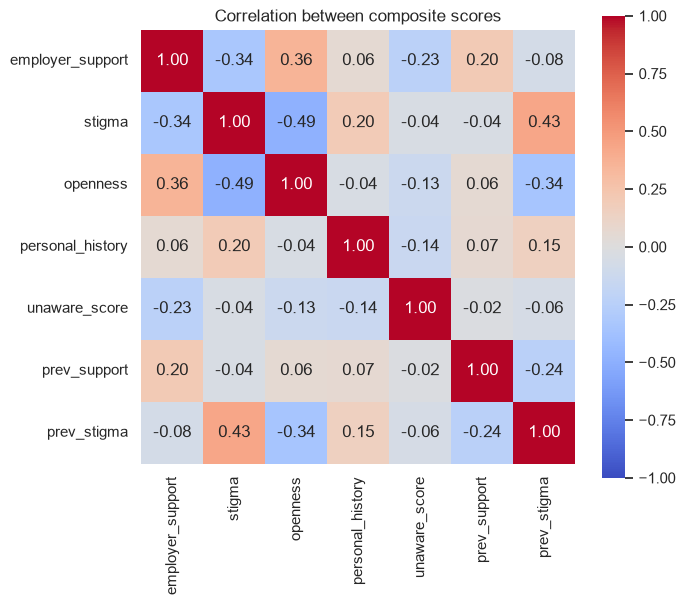

In [45]:
plt.figure(figsize=(7, 6))
sns.heatmap(clustering_input.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation between composite scores")
plt.savefig("../figures/composite_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7 summary: composite scores

Single survey questions are noisy and overlap, so related questions were combined into seven scores, each from 0 to 1. Every item was first min-max scaled to 0 to 1 (divided by its maximum, all scales start at 0), so a 0 to 4 scale does not outweigh a yes/no question. Items were then averaged within their group.

| Score | Questions | Higher means |
|---|---|---|
| employer_support | benefits, knows options, discussed, resources, anonymity, medical leave, takes MH seriously | more support |
| stigma | negative consequences (mental, physical), observed consequences, career hurt, coworkers' view, unsupportive response | worse climate |
| openness | comfortable with coworkers and supervisor, interview (mental, physical), friends and family | more open |
| personal_history | family history, past and current disorder, diagnosed, sought treatment | more history |
| unaware_score | share of six current-employer questions answered "I don't know" | less informed |
| prev_support | six previous-employer support questions | more support |
| prev_stigma | three previous-employer consequence questions + two willingness questions, flipped as 1 - x | worse climate |

The two willingness questions correlate with the stigma items (-0.32, -0.40), not with support (about 0.15), so they join prev_stigma, flipped so that higher always means worse. Folding the 11 previous-employer questions into two scores stops "no previous employer" from being counted 11 times; those 131 people sit at 0.5 on both prev scores.

Only the seven scores go into clustering (clustering_input, 1146 × 7). Work setup (company size, remote work, tech company, role, country) is kept in context and used to describe the clusters in step 10, so the clusters form on experiences HR can act on, not on country or company size. The strongest correlation is stigma vs openness (-0.49), and no pair is high enough to count one idea twice.

## 8. Dimensionality reduction

### 8.1 Standardize the scores

In [46]:
scaler = StandardScaler()
scaled = scaler.fit_transform(clustering_input)
print(scaled.shape, scaled.mean(axis=0).round(2), scaled.std(axis=0).round(2))

(1146, 7) [-0.  0. -0. -0.  0. -0. -0.] [1. 1. 1. 1. 1. 1. 1.]


### 8.2 PCA

In [47]:
pca = PCA()
pca_scores = pca.fit_transform(scaled)
print(pca.explained_variance_ratio_.round(3))
print(pca.explained_variance_ratio_.cumsum().round(3))

[0.305 0.194 0.15  0.115 0.107 0.071 0.058]
[0.305 0.499 0.649 0.764 0.871 0.942 1.   ]


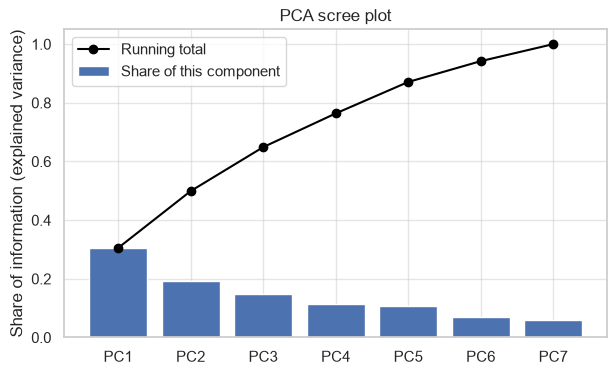

In [48]:
ratios = pca.explained_variance_ratio_
labels = [f"PC{i}" for i in range(1, len(ratios) + 1)]

plt.figure(figsize=(7, 4))
plt.bar(labels, ratios, label="Share of this component")
plt.plot(labels, ratios.cumsum(), marker="o", color="black", label="Running total")
plt.ylim(0, 1.05)
plt.ylabel("Share of information (explained variance)")
plt.title("PCA scree plot")
plt.legend()
plt.savefig("../figures/pca_scree.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
loadings = pd.DataFrame(pca.components_[:2].T,
                        index=clustering_input.columns,
                        columns=["PC1", "PC2"])
loadings.round(2).sort_values("PC1")

,PC1,PC2
openness,-0.52,-0.08
employer_support,-0.40,-0.42
prev_support,-0.21,-0.19
unaware_score,0.09,0.60
personal_history,0.13,-0.56
prev_stigma,0.45,-0.28
stigma,0.54,-0.19


### 8.3 PCA in 2D

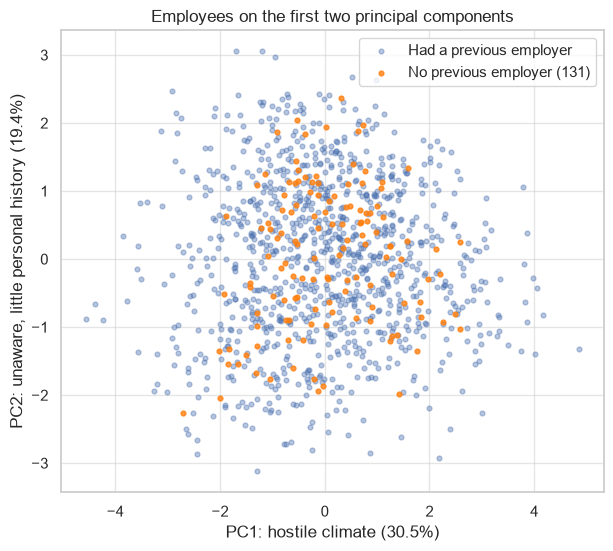

In [50]:
no_prev = (encoded["has_prev_employer"] == 0).to_numpy()
assert no_prev.sum() == 131

var = pca.explained_variance_ratio_

plt.figure(figsize=(7, 6))
plt.scatter(pca_scores[~no_prev, 0], pca_scores[~no_prev, 1],
            s=12, alpha=0.4, label="Had a previous employer")
plt.scatter(pca_scores[no_prev, 0], pca_scores[no_prev, 1],
            s=12, alpha=0.8, color="tab:orange", label="No previous employer (131)")
plt.xlabel(f"PC1: hostile climate ({var[0]:.1%})")
plt.ylabel(f"PC2: unaware, little personal history ({var[1]:.1%})")
plt.title("Employees on the first two principal components")
plt.legend()
plt.savefig("../figures/pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.4 MDS in 2D

In [51]:
mds = MDS(n_components=2, metric_mds=True, init="random", n_init=4,
          normalized_stress=True, random_state=42)
mds_scores = mds.fit_transform(scaled)
print(mds_scores.shape, "stress-1:", round(mds.stress_, 3))

(1146, 2) stress-1: 0.27


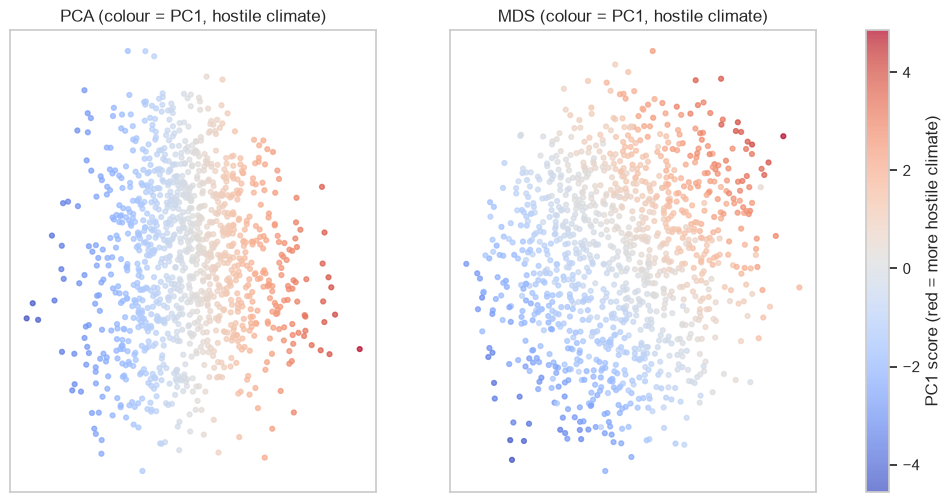

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, points, title in [(axes[0], pca_scores[:, :2], "PCA"),
                          (axes[1], mds_scores, "MDS")]:
    dots = ax.scatter(points[:, 0], points[:, 1], c=pca_scores[:, 0],
                      cmap="coolwarm", s=12, alpha=0.7)
    ax.set_title(f"{title} (colour = PC1, hostile climate)")
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(dots, ax=axes, label="PC1 score (red = more hostile climate)")
plt.savefig("../figures/pca_vs_mds.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
_, _, disparity = procrustes(pca_scores[:, :2], mds_scores)
print("Procrustes disparity PCA vs MDS:", round(disparity, 3))

Procrustes disparity PCA vs MDS: 0.078


## Step 8 summary: dimensionality reduction

**Scaling.** The seven scores were standardized (mean 0, std 1) with StandardScaler before PCA. Without it, personal_history (std 0.38, the others about 0.2) would dominate the components, because PCA follows the largest spread.

**PCA.** PC1 explains 30.5% of the variance, PC2 19.4%, together 49.9%. Three components have an eigenvalue above 1 (2.14, 1.36, 1.05), together 64.9%.

| Component | Main loadings | Meaning |
|---|---|---|
| PC1 (30.5%) | stigma +0.54, prev_stigma +0.45, openness -0.52, employer_support -0.40 | **Hostile climate**: high = much stigma now and before, not open, little support |
| PC2 (19.4%) | unaware_score +0.60, personal_history -0.56, employer_support -0.42 | **Unaware**: high = many "I don't know" answers, little personal history, little support |

**2D plot.** The employees form one continuous cloud without clearly separated groups. The 131 people without a previous employer (0.5 on both prev scores) are spread across the cloud, not clumped in one spot.

**MDS.** Metric MDS on the same standardized scores (random start, 4 runs, random_state 42) gives Kruskal stress-1 of 0.27, a poor fit by the usual rule of thumb (above 0.2), so no 2D map represents all seven scores well. After rotating and rescaling, the MDS map differs from the PCA map by a Procrustes disparity of only 0.078, so both methods show the same shape.

**Decision.** PCA is used for the plots in the report: its axes have a meaning (loadings), it gives the same result every run and takes under a second (MDS about 20 seconds). Clustering in step 9 runs on all seven standardized scores (scaled), not on the 2D coordinates, because the 2D view keeps only half of the information. Because the cloud has no clear gaps, the clusters will be segments of a continuum rather than naturally separated groups, so modest silhouette scores are expected.

## 9. Clustering

### 9.1 k-Means: elbow and silhouette

In [54]:
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(scaled, labels))

kmeans_table = pd.DataFrame({"inertia": inertias, "silhouette": silhouettes},
                            index=pd.Index(k_values, name="k"))
kmeans_table["inertia_drop"] = -kmeans_table["inertia"].diff()
kmeans_table.round(3)

,inertia,silhouette,inertia_drop
k,,,
2,6444.922,0.174,NaN
3,5593.979,0.169,850.942
4,5176.210,0.145,417.769
5,4823.225,0.140,352.985
6,4559.269,0.141,263.956
7,4334.528,0.136,224.741
8,4120.360,0.137,214.168
9,3972.930,0.134,147.430
10,3830.619,0.132,142.311


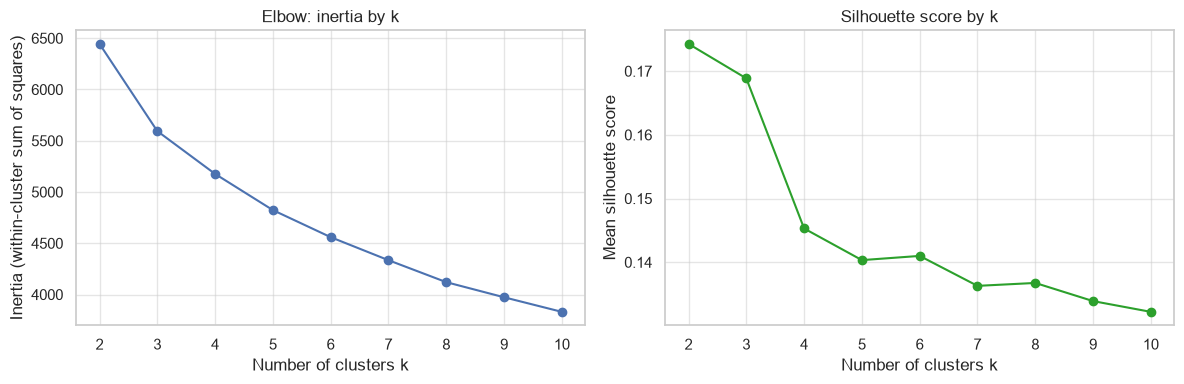

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(kmeans_table.index, kmeans_table["inertia"], marker="o")
axes[0].set_title("Elbow: inertia by k")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

axes[1].plot(kmeans_table.index, kmeans_table["silhouette"], marker="o", color="tab:green")
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette score")

plt.tight_layout()
plt.savefig("../figures/kmeans_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.2 Gaussian Mixture Model: BIC

In [56]:
gmm_k_values = range(1, 9)
floors = {"default (1e-6)": 1e-6, "0.05": 0.05, "0.1": 0.1}
bic_table = pd.DataFrame(index=pd.Index(gmm_k_values, name="k"))

for name, floor in floors.items():
    bics = []
    for k in gmm_k_values:
        gmm = GaussianMixture(n_components=k, covariance_type="full", reg_covar=floor,
                              n_init=5, random_state=42)
        gmm.fit(scaled)
        bics.append(gmm.bic(scaled))
    bic_table[f"BIC, floor {name}"] = bics

bic_table.round(0)

,"BIC, floor default (1e-6)","BIC, floor 0.05","BIC, floor 0.1"
k,,,
1,21875.0,21894.0,21944.0
2,21801.0,21832.0,21911.0
3,21434.0,21570.0,21979.0
4,21408.0,21672.0,21842.0
5,17320.0,21806.0,22017.0
6,17551.0,21970.0,22196.0
7,16215.0,22160.0,22382.0
8,17678.0,22342.0,22574.0


In [57]:
gmm_spike = GaussianMixture(n_components=7, covariance_type="full", reg_covar=1e-6,
                            n_init=5, random_state=42).fit(scaled)
spike_labels = gmm_spike.predict(scaled)

spike_check = pd.crosstab(spike_labels, no_prev, rownames=["GMM cluster"],
                          colnames=["No previous employer"])
spike_check["volume (det of covariance)"] = [np.linalg.det(c) for c in gmm_spike.covariances_]
spike_check.round(4)

No previous employer,False,True,volume (det of covariance)
GMM cluster,,,
0,237,0,0.0000
1,168,0,0.0712
2,19,131,0.0000
3,191,0,0.0044
4,155,0,0.0000
5,160,0,0.0114
6,85,0,0.0001


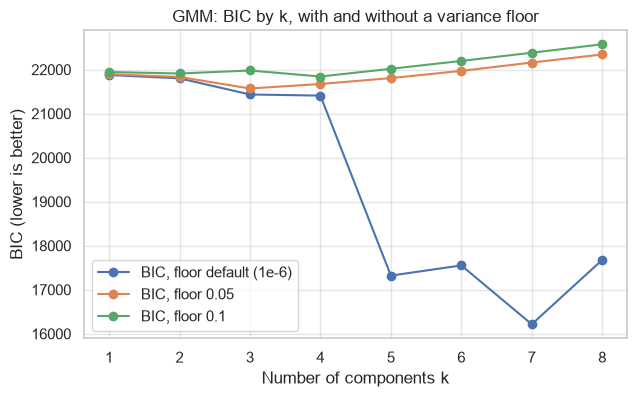

In [58]:
plt.figure(figsize=(7, 4))
for col in bic_table.columns:
    plt.plot(bic_table.index, bic_table[col], marker="o", label=col)
plt.xlabel("Number of components k")
plt.ylabel("BIC (lower is better)")
plt.title("GMM: BIC by k, with and without a variance floor")
plt.legend()
plt.savefig("../figures/gmm_bic.png", dpi=150, bbox_inches="tight")
plt.show()